<sub>**The Annotated ML Handbook** · Part V: scikit-learn · by Mahir Absar Khan</sub>

# Chapter 23: Model selection: cross-validation and hyperparameter tuning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-5-scikit-learn/23-sklearn-model-selection.ipynb) &nbsp; [📚 Contents](../../book/README.md) &nbsp; [🌐 Web edition](https://mahir-606.github.io/annotated-ml-handbook/)

*Run the setup cell first, then read and run the cells from top to bottom. Every code cell is followed by a table explaining what each line does.*

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

A single train/test split gives one noisy number. **Cross-validation** gives a more reliable estimate and lets you compare models and tune hyperparameters without touching the test set. This chapter covers the CV strategies you will need in research, including grouped and time-ordered data, then grid search, random search, learning curves and nested cross-validation.

## 23.1 k-fold cross-validation · *Beginner*

> **📖 Definitions**
>
> **Cross-validation (CV)**: repeatedly splitting the training data into fitting and validation parts and averaging the scores, for a more reliable performance estimate.
>
> **Fold**: one of the k parts the data is divided into in k-fold cross-validation.
>
> **Stratification**: splitting data so that each part keeps the same class proportions as the whole.


The training data is split into *k* folds. The model is trained *k* times, each time holding out a different fold for validation. You get *k* scores, so you can report a mean and a spread.

**cross_val_score and cross_validate**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, RepeatedStratifiedKFold)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, stratify=y, test_size=0.2, random_state=0)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

scores = cross_val_score(model, X_tr, y_tr, cv=5, scoring="roc_auc")
print(scores.round(4), f"mean={scores.mean():.4f} sd={scores.std():.4f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
res = cross_validate(model, X_tr, y_tr, cv=cv,
                     scoring=["accuracy", "roc_auc", "f1"],
                     return_train_score=True)
print(pd.DataFrame(res).mean().round(4))

[0.9933 0.9969 0.9886 0.9943 0.9995] mean=0.9945 sd=0.0036
fit_time          0.0032
score_time        0.0040
test_accuracy     0.9780
train_accuracy    0.9901
test_roc_auc      0.9947
train_roc_auc     0.9981
test_f1           0.9825
train_f1          0.9921
dtype: float64


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Import NumPy (the array library) under the short name <code>np</code>.</td></tr>
<tr><td><code>import pandas as pd</code></td><td>Import pandas (the table library) under the short name <code>pd</code>.</td></tr>
<tr><td><code>import matplotlib.pyplot as plt</code></td><td>Import Matplotlib&#x27;s plotting interface under the short name <code>plt</code>.</td></tr>
<tr><td><code>from sklearn.datasets import load_breast_cancer</code></td><td>Import <code>load_breast_cancer</code> from scikit-learn&#x27;s <code>datasets</code> module.</td></tr>
<tr><td><code>from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,</code></td><td>Import several names from scikit-learn&#x27;s <code>model_selection</code> module (the list continues on the next lines).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;KFold, StratifiedKFold, RepeatedStratifiedKFold)</code></td><td>(end of the import list)</td></tr>
<tr><td><code>from sklearn.pipeline import make_pipeline</code></td><td>Import <code>make_pipeline</code> from scikit-learn&#x27;s <code>pipeline</code> module.</td></tr>
<tr><td><code>from sklearn.preprocessing import StandardScaler</code></td><td>Import <code>StandardScaler</code> from scikit-learn&#x27;s <code>preprocessing</code> module.</td></tr>
<tr><td><code>from sklearn.linear_model import LogisticRegression</code></td><td>Import <code>LogisticRegression</code> from scikit-learn&#x27;s <code>linear_model</code> module.</td></tr>
<tr><td><code>X, y = load_breast_cancer(return_X_y=True)</code></td><td>Features and labels as arrays.</td></tr>
<tr><td><code>X_tr, X_te, y_tr, y_te = train_test_split(X, y, stratify=y, test_size=0.2, random_state=0)</code></td><td>Keep a test set aside.</td></tr>
<tr><td><code>model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))</code></td><td>The model to evaluate.</td></tr>
<tr><td><code>scores = cross_val_score(model, X_tr, y_tr, cv=5, scoring=&quot;roc_auc&quot;)</code></td><td>5 folds; one ROC AUC per fold. Pipeline = no leakage.</td></tr>
<tr><td><code>print(scores.round(4), f&quot;mean={scores.mean():.4f} sd={scores.std():.4f}&quot;)</code></td><td>Five scores, their mean and spread.</td></tr>
<tr><td><code>cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)</code></td><td>Explicit splitter: stratified, shuffled, reproducible.</td></tr>
<tr><td><code>res = cross_validate(model, X_tr, y_tr, cv=cv,</code></td><td>cross_validate returns a dict of score arrays...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;scoring=[&quot;accuracy&quot;, &quot;roc_auc&quot;, &quot;f1&quot;],</code></td><td>Several metrics at once.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;return_train_score=True)</code></td><td>Also score the training folds to spot overfitting.</td></tr>
<tr><td><code>print(pd.DataFrame(res).mean().round(4))</code></td><td>Average of each column: fit time, score time, train and test scores.</td></tr>
</table>
</details>

> **💡 Tip** · **Scoring names**
>
> `scoring=` accepts strings such as `"accuracy"`, `"balanced_accuracy"`, `"f1"`, `"f1_macro"`, `"roc_auc"`, `"average_precision"`, `"neg_log_loss"`, `"r2"`, `"neg_mean_absolute_error"`, `"neg_root_mean_squared_error"`. Error metrics are **negated** so that "higher is better" always holds; flip the sign when reporting. `sklearn.metrics.get_scorer_names()` lists them all.

**Repeated CV for more stable estimates**

In [3]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
s = cross_val_score(model, X_tr, y_tr, cv=rcv, scoring="roc_auc")
print(f"{len(s)} scores: mean={s.mean():.4f}, 2.5–97.5 percentile = {np.percentile(s, 2.5):.4f}–{np.percentile(s, 97.5):.4f}")

50 scores: mean=0.9940, 2.5–97.5 percentile = 0.9763–1.0000


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)</code></td><td>5-fold CV repeated 10 times with different shuffles = 50 scores.</td></tr>
<tr><td><code>s = cross_val_score(model, X_tr, y_tr, cv=rcv, scoring=&quot;roc_auc&quot;)</code></td><td>50 AUC scores.</td></tr>
<tr><td><code>print(f&quot;{len(s)} scores: mean={s.mean():.4f}, 2.5–97.5 percentile = {np.percentile(s, 2.5):.4f}–{np.percentile(s, 97.5):.4f}&quot;)</code></td><td>Mean and the range of the middle 95%.</td></tr>
</table>
</details>

## 23.2 Choosing the right splitter · *Intermediate*

The CV scheme must mimic how the model will be used. Getting this wrong is the most common reason published ML results fail to replicate.

| Data situation | Splitter | Why |
|---|---|---|
| i.i.d. rows, regression | `KFold(shuffle=True)` | standard |
| i.i.d. rows, classification | `StratifiedKFold(shuffle=True)` | keeps class balance in each fold |
| several rows per subject/patient/site | `GroupKFold`, `StratifiedGroupKFold` | the same subject must never appear in both train and validation |
| time series / forecasting | `TimeSeriesSplit` | always train on the past, validate on the future |
| very small datasets | `LeaveOneOut`, `RepeatedStratifiedKFold` | use every sample, reduce variance |

**Visualising splitters**

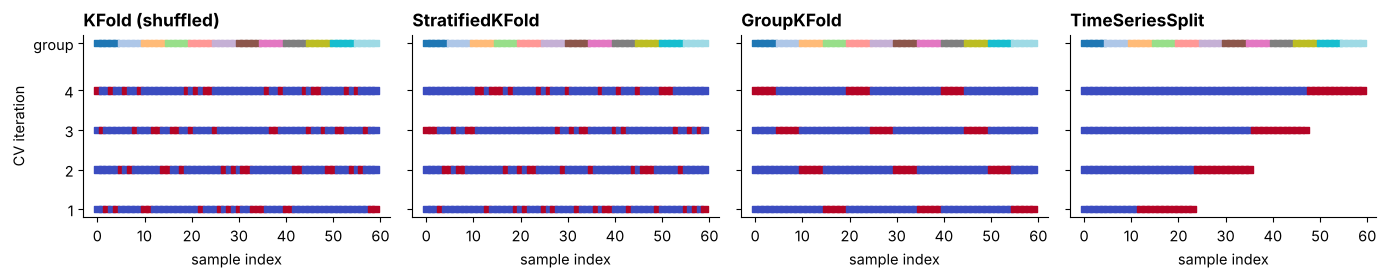

In [4]:
from sklearn.model_selection import GroupKFold, TimeSeriesSplit

n = 60
groups = np.repeat(np.arange(12), 5)
yy = np.r_[np.zeros(40), np.ones(20)]
splitters = [("KFold (shuffled)", KFold(4, shuffle=True, random_state=0)),
             ("StratifiedKFold", StratifiedKFold(4, shuffle=True, random_state=0)),
             ("GroupKFold", GroupKFold(4)),
             ("TimeSeriesSplit", TimeSeriesSplit(4))]
fig, axes = plt.subplots(1, 4, figsize=(14, 2.9), sharey=True)
for ax, (name, sp) in zip(axes, splitters):
    g = groups if name == "GroupKFold" else None
    for i, (tr, va) in enumerate(sp.split(np.zeros((n, 1)), yy, g)):
        row = np.full(n, np.nan); row[tr] = 0; row[va] = 1
        ax.scatter(range(n), [i] * n, c=row, cmap="coolwarm", marker="s", s=22, vmin=0, vmax=1)
    ax.scatter(range(n), [4.2] * n, c=groups, cmap="tab20", marker="s", s=22)
    ax.set(title=name, xlabel="sample index", yticks=[0, 1, 2, 3, 4.2], yticklabels=["1", "2", "3", "4", "group"])
    ax.grid(False)
axes[0].set_ylabel("CV iteration")
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.model_selection import GroupKFold, TimeSeriesSplit</code></td><td>Import <code>GroupKFold</code> and <code>TimeSeriesSplit</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>n = 60</code></td><td>60 rows for the illustration.</td></tr>
<tr><td><code>groups = np.repeat(np.arange(12), 5)</code></td><td>12 subjects with 5 rows each.</td></tr>
<tr><td><code>yy = np.r_[np.zeros(40), np.ones(20)]</code></td><td>Imbalanced labels: 40 zeros, 20 ones.</td></tr>
<tr><td><code>splitters = [(&quot;KFold (shuffled)&quot;, KFold(4, shuffle=True, random_state=0)),</code></td><td>Four splitters to compare, each with 4 folds...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;(&quot;StratifiedKFold&quot;, StratifiedKFold(4, shuffle=True, random_state=0)),</code></td><td>...stratified...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;(&quot;GroupKFold&quot;, GroupKFold(4)),</code></td><td>...grouped...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;(&quot;TimeSeriesSplit&quot;, TimeSeriesSplit(4))]</code></td><td>...and time-ordered.</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 4, figsize=(14, 2.9), sharey=True)</code></td><td>Four panels sharing the y-axis.</td></tr>
<tr><td><code>for ax, (name, sp) in zip(axes, splitters):</code></td><td>Loop over <code>zip(axes, splitters)</code>, naming each item <code>ax, (name, sp)</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;g = groups if name == &quot;GroupKFold&quot; else None</code></td><td>Only GroupKFold uses groups.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;for i, (tr, va) in enumerate(sp.split(np.zeros((n, 1)), yy, g)):</code></td><td>Loop over <code>enumerate(sp.split(np.zeros((n, 1)), yy, g))</code>, naming each item <code>i, (tr, va)</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;row = np.full(n, np.nan); row[tr] = 0; row[va] = 1</code></td><td>0 for training rows, 1 for validation rows, NaN for unused.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;ax.scatter(range(n), [i] * n, c=row, cmap=&quot;coolwarm&quot;, marker=&quot;s&quot;, s=22, vmin=0, vmax=1)</code></td><td>One row of squares per iteration (blue = train, red = validation).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.scatter(range(n), [4.2] * n, c=groups, cmap=&quot;tab20&quot;, marker=&quot;s&quot;, s=22)</code></td><td>A band showing each sample&#x27;s group.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.set(title=name, xlabel=&quot;sample index&quot;, yticks=[0, 1, 2, 3, 4.2], yticklabels=[&quot;1&quot;, &quot;2&quot;, &quot;3&quot;, &quot;4&quot;, &quot;group&quot;])</code></td><td>Label the rows.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.grid(False)</code></td><td>Turn off the grid lines on this panel.</td></tr>
<tr><td><code>axes[0].set_ylabel(&quot;CV iteration&quot;)</code></td><td>y label on the first panel.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Adjust spacing so titles and labels don&#x27;t overlap.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

### 23.2.1 Grouped data: the leakage you don't see · *Intermediate*

**Repeated measurements: KFold is optimistic, GroupKFold is honest**

In [5]:
from sklearn.ensemble import RandomForestClassifier
rng = np.random.default_rng(0)
n_subj, per = 40, 10
subj = np.repeat(np.arange(n_subj), per)
subj_effect = rng.normal(0, 1, (n_subj, 5))[subj]
label = rng.integers(0, 2, n_subj)[subj]
Xg = subj_effect + rng.normal(0, 0.3, (n_subj * per, 5))
rf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
naive = cross_val_score(rf, Xg, label, cv=KFold(5, shuffle=True, random_state=0)).mean()
grouped = cross_val_score(rf, Xg, label, cv=GroupKFold(5), groups=subj).mean()
print(f"KFold accuracy:      {naive:.2f}  <- the model recognises subjects it has already seen")
print(f"GroupKFold accuracy: {grouped:.2f}  <- honest: near chance")

KFold accuracy:      0.88  <- the model recognises subjects it has already seen
GroupKFold accuracy: 0.49  <- honest: near chance


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.ensemble import RandomForestClassifier</code></td><td>Import <code>RandomForestClassifier</code> from scikit-learn&#x27;s <code>ensemble</code> module.</td></tr>
<tr><td><code>rng = np.random.default_rng(0)</code></td><td>Seeded generator.</td></tr>
<tr><td><code>n_subj, per = 40, 10</code></td><td>40 subjects, 10 recordings each.</td></tr>
<tr><td><code>subj = np.repeat(np.arange(n_subj), per)</code></td><td>40 subjects x 10 recordings each.</td></tr>
<tr><td><code>subj_effect = rng.normal(0, 1, (n_subj, 5))[subj]</code></td><td>Each subject has a personal &quot;fingerprint&quot; in the features.</td></tr>
<tr><td><code>label = rng.integers(0, 2, n_subj)[subj]</code></td><td>One label per subject, unrelated to the features: no real signal.</td></tr>
<tr><td><code>Xg = subj_effect + rng.normal(0, 0.3, (n_subj * per, 5))</code></td><td>Recordings = subject fingerprint + small noise.</td></tr>
<tr><td><code>rf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)</code></td><td>A flexible model that can memorise fingerprints.</td></tr>
<tr><td><code>naive = cross_val_score(rf, Xg, label, cv=KFold(5, shuffle=True, random_state=0)).mean()</code></td><td>Rows of the same subject land in both training and validation.</td></tr>
<tr><td><code>grouped = cross_val_score(rf, Xg, label, cv=GroupKFold(5), groups=subj).mean()</code></td><td>Pass <code>groups=</code> so whole subjects stay together.</td></tr>
<tr><td><code>print(f&quot;KFold accuracy:      {naive:.2f}  &lt;- the model recognises subjects it has already seen&quot;)</code></td><td>Inflated.</td></tr>
<tr><td><code>print(f&quot;GroupKFold accuracy: {grouped:.2f}  &lt;- honest: near chance&quot;)</code></td><td>Realistic.</td></tr>
</table>
</details>

> **🔬 Research practice** · **If you have multiple samples per subject, group by subject**
>
> Patients with several scans, participants with several trials, sites with many plots, molecules with several conformers: the unit of generalisation is the **subject**, so the split must be by subject. Report it explicitly in your Methods.

### 23.2.2 Time series · *Intermediate*

**Forward-chaining validation**

In [6]:
tscv = TimeSeriesSplit(n_splits=4, test_size=10)
for i, (tr, va) in enumerate(tscv.split(np.arange(60))):
    print(f"fold {i}: train {tr.min()}–{tr.max()}  validate {va.min()}–{va.max()}")

fold 0: train 0–19  validate 20–29
fold 1: train 0–29  validate 30–39
fold 2: train 0–39  validate 40–49
fold 3: train 0–49  validate 50–59


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>tscv = TimeSeriesSplit(n_splits=4, test_size=10)</code></td><td>4 splits, each validating on the next 10 steps.</td></tr>
<tr><td><code>for i, (tr, va) in enumerate(tscv.split(np.arange(60))):</code></td><td>Loop over <code>enumerate(tscv.split(np.arange(60)))</code>, naming each item <code>i, (tr, va)</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(f&quot;fold {i}: train {tr.min()}–{tr.max()}  validate {va.min()}–{va.max()}&quot;)</code></td><td>Validation always lies after training.</td></tr>
</table>
</details>

## 23.3 Hyperparameter tuning with GridSearchCV · *Intermediate*

> **📖 Definitions**
>
> **Hyperparameter tuning**: searching for the hyperparameter values that give the best cross-validated performance.
>
> **Grid search**: trying every combination of hyperparameter values from a predefined grid. **Random search** samples combinations at random instead.


`GridSearchCV` tries every combination in a grid, scores each with cross-validation, and refits the best one on the whole training set.

**Tuning an SVM inside a pipeline**

In [7]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(StandardScaler(), SVC())
param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.001, 0.01, 0.1],
    "svc__kernel": ["rbf"],
}
search = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=0),
                      scoring="roc_auc", n_jobs=-1, return_train_score=True)
search.fit(X_tr, y_tr)
print("best params:", search.best_params_)
print("best CV ROC AUC:", round(search.best_score_, 4))
print("test ROC AUC (once!):", round(search.score(X_te, y_te), 4))
cvres = pd.DataFrame(search.cv_results_)
print(cvres[["param_svc__C", "param_svc__gamma", "mean_test_score", "std_test_score", "rank_test_score"]]
      .sort_values("rank_test_score").head(5).round(4).to_string(index=False))

best params: {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
best CV ROC AUC: 0.9966
test ROC AUC (once!): 0.9934
 param_svc__C param_svc__gamma  mean_test_score  std_test_score  rank_test_score
          1.0            scale           0.9966          0.0045                1
          1.0             0.01           0.9962          0.0052                2
         10.0            scale           0.9962          0.0046                2
         10.0             0.01           0.9956          0.0059                4
        100.0            0.001           0.9954          0.0060                5


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.svm import SVC</code></td><td>Import <code>SVC</code> from scikit-learn&#x27;s <code>svm</code> module.</td></tr>
<tr><td><code>from sklearn.model_selection import GridSearchCV</code></td><td>Import <code>GridSearchCV</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>pipe = make_pipeline(StandardScaler(), SVC())</code></td><td>The pipeline to tune.</td></tr>
<tr><td><code>param_grid = {</code></td><td>The grid of values to try:</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;svc__C&quot;: [0.1, 1, 10, 100],</code></td><td>step-name__parameter: reaches inside the pipeline.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;svc__gamma&quot;: [&quot;scale&quot;, 0.001, 0.01, 0.1],</code></td><td>Kernel width: how far each training point&#x27;s influence reaches.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;svc__kernel&quot;: [&quot;rbf&quot;],</code></td><td>Fixed: the RBF kernel.</td></tr>
<tr><td><code>}</code></td><td>Close the dictionary opened above.</td></tr>
<tr><td><code>search = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=0),</code></td><td>Score every combination with stratified 5-fold CV...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;scoring=&quot;roc_auc&quot;, n_jobs=-1, return_train_score=True)</code></td><td>n_jobs=-1 uses all CPU cores.</td></tr>
<tr><td><code>search.fit(X_tr, y_tr)</code></td><td>16 combinations x 5 folds = 80 fits, then 1 refit.</td></tr>
<tr><td><code>print(&quot;best params:&quot;, search.best_params_)</code></td><td>The winning combination.</td></tr>
<tr><td><code>print(&quot;best CV ROC AUC:&quot;, round(search.best_score_, 4))</code></td><td>Its mean CV score.</td></tr>
<tr><td><code>print(&quot;test ROC AUC (once!):&quot;, round(search.score(X_te, y_te), 4))</code></td><td>search behaves like the refitted best model.</td></tr>
<tr><td><code>cvres = pd.DataFrame(search.cv_results_)</code></td><td>Every combination&#x27;s mean/std scores.</td></tr>
<tr><td><code>print(cvres[[&quot;param_svc__C&quot;, &quot;param_svc__gamma&quot;, &quot;mean_test_score&quot;, &quot;std_test_score&quot;, &quot;rank_test_score&quot;]]</code></td><td>The top 5 combinations...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;.sort_values(&quot;rank_test_score&quot;).head(5).round(4).to_string(index=False))</code></td><td>...sorted by rank.</td></tr>
</table>
</details>

**See the landscape**

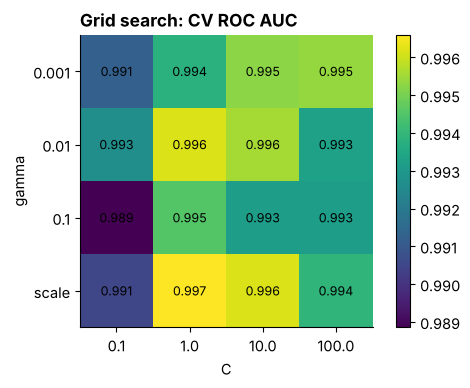

In [8]:
pivot = cvres.pivot_table(index="param_svc__gamma", columns="param_svc__C", values="mean_test_score")
pivot.index = pivot.index.astype(str)
fig, ax = plt.subplots(figsize=(6, 3.8))
im = ax.imshow(pivot.values, cmap="viridis")
ax.set(xticks=range(pivot.shape[1]), xticklabels=pivot.columns, yticks=range(pivot.shape[0]), yticklabels=pivot.index,
       xlabel="C", ylabel="gamma", title="Grid search: CV ROC AUC")
for (i, j), v in np.ndenumerate(pivot.values):
    ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white" if v < pivot.values.max() - 0.01 else "black", fontsize=9)
ax.grid(False)
fig.colorbar(im)
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>pivot = cvres.pivot_table(index=&quot;param_svc__gamma&quot;, columns=&quot;param_svc__C&quot;, values=&quot;mean_test_score&quot;)</code></td><td>Reshape into a gamma x C grid.</td></tr>
<tr><td><code>pivot.index = pivot.index.astype(str)</code></td><td>Text labels (mixing &quot;scale&quot; and numbers).</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(6, 3.8))</code></td><td>One panel.</td></tr>
<tr><td><code>im = ax.imshow(pivot.values, cmap=&quot;viridis&quot;)</code></td><td>Draw the grid as a heatmap.</td></tr>
<tr><td><code>ax.set(xticks=range(pivot.shape[1]), xticklabels=pivot.columns, yticks=range(pivot.shape[0]), yticklabels=pivot.index,</code></td><td>Tick labels from the grid values...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;xlabel=&quot;C&quot;, ylabel=&quot;gamma&quot;, title=&quot;Grid search: CV ROC AUC&quot;)</code></td><td>...axis labels and title.</td></tr>
<tr><td><code>for (i, j), v in np.ndenumerate(pivot.values):</code></td><td>Loop over <code>np.ndenumerate(pivot.values)</code>, naming each item <code>(i, j), v</code>.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.text(j, i, f&quot;{v:.3f}&quot;, ha=&quot;center&quot;, va=&quot;center&quot;, color=&quot;white&quot; if v &lt; pivot.values.max() - 0.01 else &quot;black&quot;, fontsize=9)</code></td><td>Write each score in its cell, black on the brightest cells.</td></tr>
<tr><td><code>ax.grid(False)</code></td><td>Turn off the grid lines on this panel.</td></tr>
<tr><td><code>fig.colorbar(im)</code></td><td>Colour scale.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

### 23.3.1 Searching over models and preprocessing too · *Advanced*

A grid can be a list of dicts, and a pipeline step can itself be a hyperparameter.

**One search, several model families**

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
pipe = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())])
grid = [
    {"clf": [LogisticRegression(max_iter=2000)], "clf__C": [0.01, 0.1, 1, 10]},
    {"clf": [RandomForestClassifier(random_state=0)], "clf__n_estimators": [200], "clf__max_depth": [None, 5],
     "scale": ["passthrough"]},
]
gs = GridSearchCV(pipe, grid, cv=5, scoring="roc_auc", n_jobs=-1).fit(X_tr, y_tr)
print(gs.best_params_["clf"], round(gs.best_score_, 4))

RandomForestClassifier(random_state=0) 0.9958


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.ensemble import RandomForestClassifier</code></td><td>Import <code>RandomForestClassifier</code> from scikit-learn&#x27;s <code>ensemble</code> module.</td></tr>
<tr><td><code>from sklearn.pipeline import Pipeline</code></td><td>Import <code>Pipeline</code> from scikit-learn&#x27;s <code>pipeline</code> module.</td></tr>
<tr><td><code>pipe = Pipeline([(&quot;scale&quot;, StandardScaler()), (&quot;clf&quot;, LogisticRegression())])</code></td><td>A pipeline whose &quot;clf&quot; step will be swapped.</td></tr>
<tr><td><code>grid = [</code></td><td>A list of grids, each searched separately:</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;{&quot;clf&quot;: [LogisticRegression(max_iter=2000)], &quot;clf__C&quot;: [0.01, 0.1, 1, 10]},</code></td><td>Logistic regression with 4 values of C.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;{&quot;clf&quot;: [RandomForestClassifier(random_state=0)], &quot;clf__n_estimators&quot;: [200], &quot;clf__max_depth&quot;: [None, 5],</code></td><td>Random forest with two depths...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&quot;scale&quot;: [&quot;passthrough&quot;]},</code></td><td>&quot;passthrough&quot; disables a step (trees don&#x27;t need scaling).</td></tr>
<tr><td><code>]</code></td><td>Close the list opened above.</td></tr>
<tr><td><code>gs = GridSearchCV(pipe, grid, cv=5, scoring=&quot;roc_auc&quot;, n_jobs=-1).fit(X_tr, y_tr)</code></td><td>Search both families.</td></tr>
<tr><td><code>print(gs.best_params_[&quot;clf&quot;], round(gs.best_score_, 4))</code></td><td>The winning model and its CV score.</td></tr>
</table>
</details>

## 23.4 RandomizedSearchCV and successive halving · *Intermediate*

When there are many hyperparameters, sampling random combinations from distributions finds good settings with far fewer fits than a full grid.

**Random search over a gradient-boosting model**

In [10]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier

dist = {
    "learning_rate": loguniform(1e-3, 0.5),
    "max_leaf_nodes": randint(8, 64),
    "min_samples_leaf": randint(5, 60),
    "l2_regularization": loguniform(1e-4, 10),
}
rs = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=0), dist, n_iter=25,
                        cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc",
                        random_state=0, n_jobs=-1)
rs.fit(X_tr, y_tr)
print({k: round(float(v), 4) if isinstance(v, float) else int(v) for k, v in rs.best_params_.items()})
print("best CV ROC AUC:", round(rs.best_score_, 4))

{'l2_regularization': 5.2329, 'learning_rate': 0.0692, 'max_leaf_nodes': 39, 'min_samples_leaf': 6}
best CV ROC AUC: 0.993


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from scipy.stats import loguniform, randint</code></td><td>Import <code>loguniform</code> and <code>randint</code> from <code>scipy.stats</code>.</td></tr>
<tr><td><code>from sklearn.model_selection import RandomizedSearchCV</code></td><td>Import <code>RandomizedSearchCV</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>from sklearn.ensemble import HistGradientBoostingClassifier</code></td><td>Import <code>HistGradientBoostingClassifier</code> from scikit-learn&#x27;s <code>ensemble</code> module.</td></tr>
<tr><td><code>dist = {</code></td><td>Distributions to sample hyperparameters from:</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;learning_rate&quot;: loguniform(1e-3, 0.5),</code></td><td>Sample on a log scale: good for rates and regularisation strengths.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;max_leaf_nodes&quot;: randint(8, 64),</code></td><td>Integers 8..63.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;min_samples_leaf&quot;: randint(5, 60),</code></td><td>Integers 5..59.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&quot;l2_regularization&quot;: loguniform(1e-4, 10),</code></td><td>Log-uniform from 0.0001 to 10.</td></tr>
<tr><td><code>}</code></td><td>Close the dictionary opened above.</td></tr>
<tr><td><code>rs = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=0), dist, n_iter=25,</code></td><td>Try 25 random combinations...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring=&quot;roc_auc&quot;,</code></td><td>...each scored by 5-fold CV ROC AUC...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;random_state=0, n_jobs=-1)</code></td><td>...reproducibly, in parallel.</td></tr>
<tr><td><code>rs.fit(X_tr, y_tr)</code></td><td>Run the search.</td></tr>
<tr><td><code>print({k: round(float(v), 4) if isinstance(v, float) else int(v) for k, v in rs.best_params_.items()})</code></td><td>Convert NumPy numbers to plain Python numbers for tidy printing.</td></tr>
<tr><td><code>print(&quot;best CV ROC AUC:&quot;, round(rs.best_score_, 4))</code></td><td>Best mean CV score.</td></tr>
</table>
</details>

> **💡 Tip** · **Beyond random search**
>
> `HalvingGridSearchCV` / `HalvingRandomSearchCV` (enable with `from sklearn.experimental import enable_halving_search_cv`) discard poor candidates early. **Optuna** performs Bayesian optimisation and integrates well with scikit-learn and Keras.

## 23.5 Learning curves and validation curves · *Intermediate*

> **📖 Definitions**
>
> **Learning curve**: training and validation scores plotted against training-set size; it shows whether more data would help.
>
> **Validation curve**: training and validation scores plotted against one hyperparameter; it shows under- and overfitting.

**Diagnose bias vs variance**

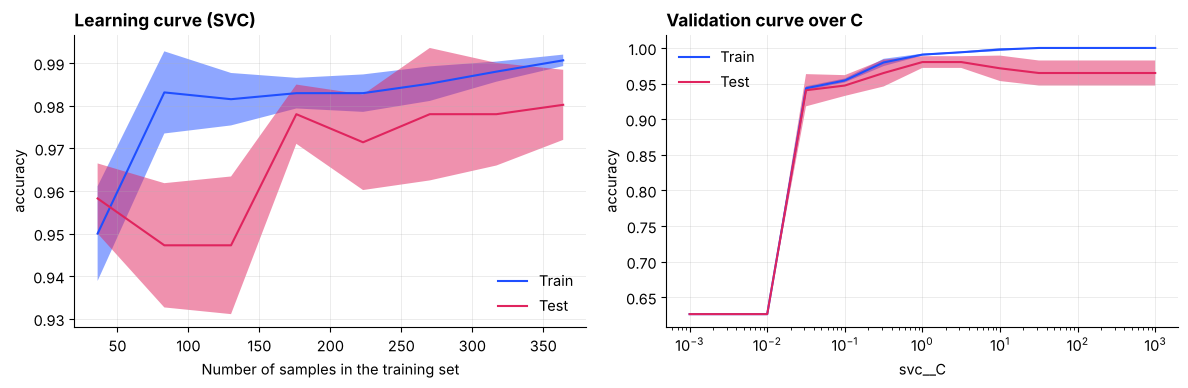

In [11]:
from sklearn.model_selection import LearningCurveDisplay, ValidationCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
LearningCurveDisplay.from_estimator(make_pipeline(StandardScaler(), SVC()), X_tr, y_tr,
                                    train_sizes=np.linspace(0.1, 1.0, 8), cv=5, scoring="accuracy",
                                    ax=axes[0], score_name="accuracy", n_jobs=-1)
axes[0].set_title("Learning curve (SVC)")
ValidationCurveDisplay.from_estimator(make_pipeline(StandardScaler(), SVC()), X_tr, y_tr,
                                      param_name="svc__C", param_range=np.logspace(-3, 3, 13), cv=5,
                                      scoring="accuracy", ax=axes[1], score_name="accuracy", n_jobs=-1)
axes[1].set(xscale="log", title="Validation curve over C")
plt.tight_layout()
plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.model_selection import LearningCurveDisplay, ValidationCurveDisplay</code></td><td>Import <code>LearningCurveDisplay</code> and <code>ValidationCurveDisplay</code> from scikit-learn&#x27;s <code>model_selection</code> module.</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 2, figsize=(12, 4))</code></td><td>Two panels.</td></tr>
<tr><td><code>LearningCurveDisplay.from_estimator(make_pipeline(StandardScaler(), SVC()), X_tr, y_tr,</code></td><td>Learning curve for a scaled SVC...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;train_sizes=np.linspace(0.1, 1.0, 8), cv=5, scoring=&quot;accuracy&quot;,</code></td><td>...8 training sizes from 10% to 100%, 5-fold CV...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;ax=axes[0], score_name=&quot;accuracy&quot;, n_jobs=-1)</code></td><td>Trains on growing subsets of the data.</td></tr>
<tr><td><code>axes[0].set_title(&quot;Learning curve (SVC)&quot;)</code></td><td>Title.</td></tr>
<tr><td><code>ValidationCurveDisplay.from_estimator(make_pipeline(StandardScaler(), SVC()), X_tr, y_tr,</code></td><td>Validation curve for the same model...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;param_name=&quot;svc__C&quot;, param_range=np.logspace(-3, 3, 13), cv=5,</code></td><td>...sweeping C from 0.001 to 1000...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;scoring=&quot;accuracy&quot;, ax=axes[1], score_name=&quot;accuracy&quot;, n_jobs=-1)</code></td><td>Sweeps ONE hyperparameter.</td></tr>
<tr><td><code>axes[1].set(xscale=&quot;log&quot;, title=&quot;Validation curve over C&quot;)</code></td><td>Log x-axis.</td></tr>
<tr><td><code>plt.tight_layout()</code></td><td>Adjust spacing so titles and labels don&#x27;t overlap.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw the figure (in a script this opens a window; in Jupyter it appears below the cell).</td></tr>
</table>
</details>

## 23.6 Nested cross-validation: an unbiased estimate after tuning · *Advanced*

> **📖 Definitions**
>
> **Nested cross-validation**: an outer CV loop that estimates performance, with an inner CV loop inside each outer fold that tunes hyperparameters.


`search.best_score_` is optimistically biased, because the same folds were used to choose the hyperparameters. When you have no separate test set (common with small research datasets), wrap the search inside an outer CV loop.

**Inner loop tunes, outer loop evaluates**

In [12]:
inner = StratifiedKFold(5, shuffle=True, random_state=1)
outer = StratifiedKFold(5, shuffle=True, random_state=2)
tuned_svc = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                         {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.001]},
                         cv=inner, scoring="roc_auc", n_jobs=-1)
nested = cross_val_score(tuned_svc, X, y, cv=outer, scoring="roc_auc")
tuned_svc.fit(X, y)
print(f"non-nested best_score_: {tuned_svc.best_score_:.4f}")
print(f"nested CV estimate:     {nested.mean():.4f} ± {nested.std():.4f}")

non-nested best_score_: 0.9960
nested CV estimate:     0.9968 ± 0.0054


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>inner = StratifiedKFold(5, shuffle=True, random_state=1)</code></td><td>Inner CV: used to choose hyperparameters.</td></tr>
<tr><td><code>outer = StratifiedKFold(5, shuffle=True, random_state=2)</code></td><td>Outer CV: used to estimate performance.</td></tr>
<tr><td><code>tuned_svc = GridSearchCV(make_pipeline(StandardScaler(), SVC()),</code></td><td>A grid search object (not fitted yet)...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;{&quot;svc__C&quot;: [0.1, 1, 10, 100], &quot;svc__gamma&quot;: [&quot;scale&quot;, 0.01, 0.001]},</code></td><td>...with 12 combinations...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;cv=inner, scoring=&quot;roc_auc&quot;, n_jobs=-1)</code></td><td>...tuned with the inner CV.</td></tr>
<tr><td><code>nested = cross_val_score(tuned_svc, X, y, cv=outer, scoring=&quot;roc_auc&quot;)</code></td><td>Each outer fold runs a complete grid search on its own training part.</td></tr>
<tr><td><code>tuned_svc.fit(X, y)</code></td><td>A separate, ordinary (non-nested) search on all the data, for comparison.</td></tr>
<tr><td><code>print(f&quot;non-nested best_score_: {tuned_svc.best_score_:.4f}&quot;)</code></td><td>Potentially optimistic.</td></tr>
<tr><td><code>print(f&quot;nested CV estimate:     {nested.mean():.4f} ± {nested.std():.4f}&quot;)</code></td><td>Unbiased estimate with its spread.</td></tr>
</table>
</details>

Here the two numbers agree closely: the dataset is easy and the grid is small, so there is little room for the search to overfit the folds. With large search spaces, small samples or noisy targets the non-nested score can be inflated by several points, and you cannot know in advance which situation you are in.

> **🔬 Research practice** · **Which number goes in the paper?**
>
> Report the **nested CV** score (or the score on an untouched test set) as your performance estimate, never `best_score_` from the same search. Report the hyperparameter search space and the selection metric, so others can reproduce the tuning.

> **✍️ Try it yourself**
>
> 1. Tune `n_neighbors` (1–30) and `weights` (`"uniform"`, `"distance"`) for kNN on the breast-cancer data with `GridSearchCV`.
> 2. Use `cross_validate(..., return_estimator=True)` to inspect how much logistic-regression coefficients vary across folds.
> 3. Compare 5-fold and 10-fold CV estimates and their standard deviations for the same model.
>
> *Worked solutions:* [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 23*.

---

⬅️ [Chapter 22: Classification: predicting categories](22-sklearn-classification.ipynb) · [📚 Contents](../../book/README.md) · [Chapter 24: Unsupervised learning: clustering and dimensionality reduction](24-sklearn-unsupervised.ipynb) ➡️